In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from tensorflow import keras
from sklearn.preprocessing import normalize
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from keras.layers import Dense, Flatten, Dropout

In [ ]:
data = fetch_california_housing()

In [ ]:
x = data.data
y = data.target

In [ ]:
imputer = SimpleImputer(strategy="mean")
x = imputer.fit_transform(x)

In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
xtrain = normalize(xtrain)
xtest = normalize(xtest)

In [ ]:
model = keras.Sequential([
    Dense(100, activation="relu"),
    Dropout(0.2),
    Dense(100, activation="relu"),
    Dropout(0.2),
    Dense(100, activation="relu"),
    Dropout(0.2),
    Dense(100, activation="relu"),
    Dropout(0.2),
    Dense(50, activation="relu"),
    Dropout(0.1),
    Dense(50, activation="relu"),
    Dropout(0.1),
    Dense(50, activation="relu"),
    Dropout(0.1),
    Dense(1, activation="linear")
])

In [ ]:
model.compile(loss=keras.losses.MeanSquaredError(), optimizer= "adam", metrics=["accuracy"])

In [139]:
history = model.fit(xtrain, ytrain, epochs=100, batch_size= 32)

Epoch 1/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.0031 - loss: 1.5216
Epoch 2/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.0032 - loss: 1.3818
Epoch 3/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.0032 - loss: 1.3373
Epoch 4/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.0032 - loss: 1.0567
Epoch 5/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.0032 - loss: 0.8586
Epoch 6/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.0032 - loss: 0.7883
Epoch 7/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.0032 - loss: 0.7437
Epoch 8/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.0032 - loss: 0.7212
Epoch 9/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.0032 - loss: 0.7150
Epoch 10/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.0032 - loss: 0.6938
Epoch 11/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.0032 - loss: 0.6712
Epoch 12/100
516/516 ━━━━━━━━━━━━━━━━━━━

In [140]:
score1 = model.evaluate(xtest, ytest)
score2 = model.evaluate(xtrain, ytrain)
score1, score2

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0022 - loss: 0.5228
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.0032 - loss: 0.4996


([0.5227957963943481, 0.0021802326664328575],
 [0.49960196018218994, 0.0032097867224365473])

In [141]:
i = 442
ypred = model.predict(np.array([xtest[i]]))
ypred, ytest[i]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step


(array([[3.5472713]], dtype=float32), np.float64(4.272))

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


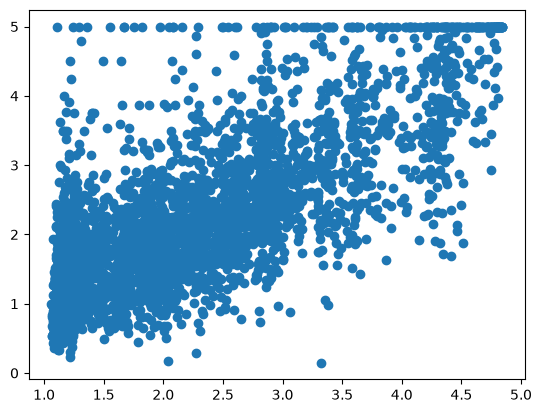

In [142]:
ypred = model.predict(xtest)
plt.scatter(ypred, ytest)
plt.show()